# Lab 5 PCA and Autoencoder Super-Resolution for EO Images

In this notebook we do two tasks on Earth Observation images.
- Task 1 extracts patches for ocean, forests, and man-made areas, runs PCA with 3 components, and plots 3D and 2D scatter plots to check clustering.
- Task 2 adapts the MNIST autoencoder for Super-Resolution on an EO image, checks PSNR, SSIM and visual quality, tests a residual CNN version, and answers the questions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skimage import transform
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Add
from tensorflow.keras.models import Model
import ee
import requests
import tifffile
from io import BytesIO

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

# Initialize Google Earth Engine (same as in lab4)
try:
    ee.Initialize(project='timelapselandsatproject')
except Exception:
    ee.Initialize()

def get_s2_composite(aoi, bands, start='2023-06-01', end='2023-08-31'):
    return (
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterDate(start, end)
        .filterBounds(aoi)
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
        .select(bands)
        .median()
        .clip(aoi)
    )

def download_ee_image_as_array(image, aoi, scale=20, norm_factor=10000.0):
    url = image.getDownloadURL({
        'scale': scale,
        'region': aoi,
        'format': 'GEO_TIFF'
    })
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    arr = np.array(tifffile.imread(BytesIO(response.content)), dtype=np.float32)
    arr = np.nan_to_num(arr, nan=0.0)
    return np.clip(arr / norm_factor, 0.0, 1.0)

TensorFlow version: 2.21.0


## Task 1 PCA on Real Sentinel-2 Land-Cover Patches

We fetch real 4-band Sentinel-2 images (Red, Green, Blue, and NIR bands B4, B3, B2, B8) via Google Earth Engine for three regions
- Baltic Sea for ocean (low reflectance in visible bands and very low in NIR)
- Kampinos Forest for forests (moderate green and very high NIR)
- Warsaw city center for man-made areas (bright visible bands with urban street and building texture)

Then we extract 100 patches of size 16x16x4 per class, flatten them into 1024 features, standardize the values, and reduce the dimensionality to 3 principal components (PC1, PC2, PC3).

Ocean shape: (251, 433, 4) | Forest shape: (252, 408, 4) | Urban shape: (251, 407, 4)


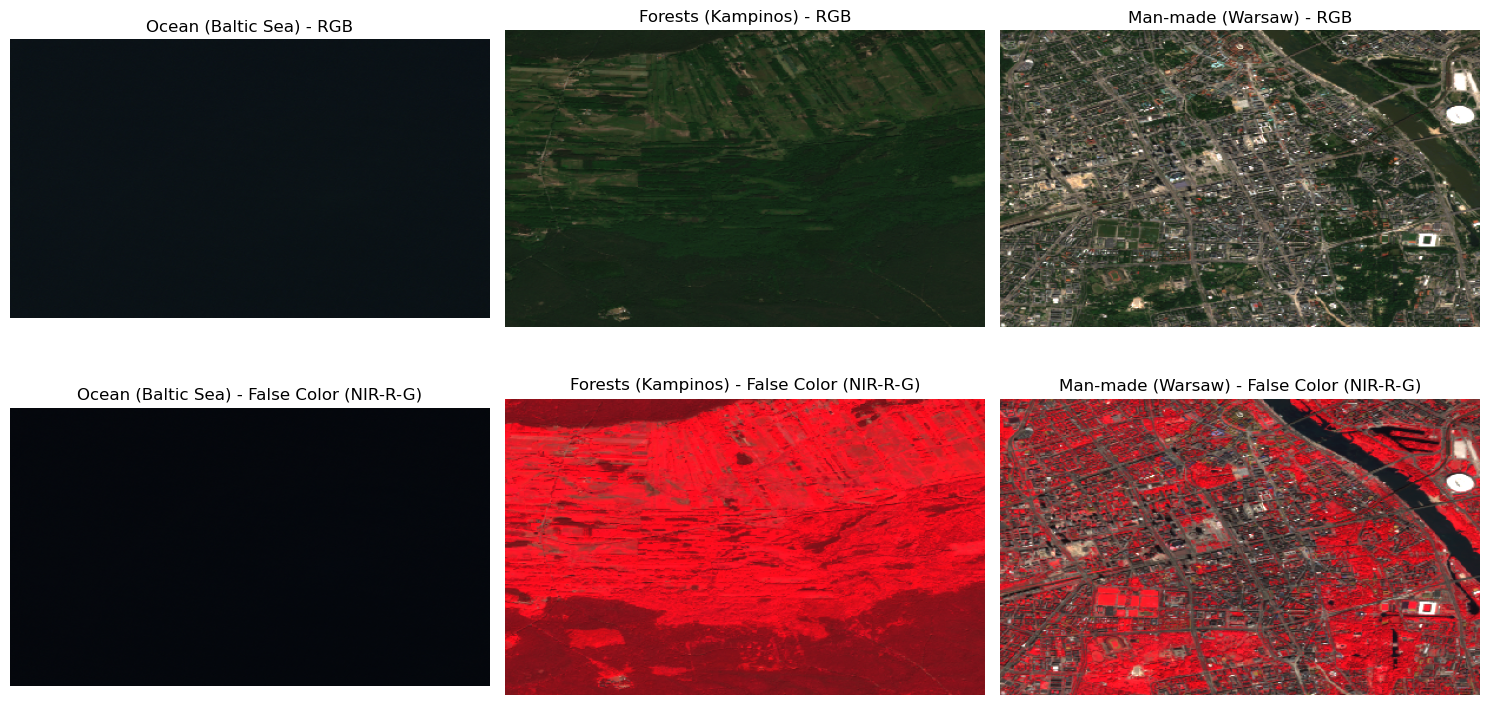

In [2]:
# Define 3 rectangular ROIs for Ocean, Forests, and Man-made
ocean_aoi  = ee.Geometry.Point([18.9500, 54.8500]).buffer(2500).bounds()  # Baltic Sea
forest_aoi = ee.Geometry.Point([20.5500, 52.3200]).buffer(2500).bounds()  # Kampinos Forest
urban_aoi  = ee.Geometry.Point([21.0122, 52.2297]).buffer(2500).bounds()  # Warsaw

bands_4 = ['B4', 'B3', 'B2', 'B8']  # R, G, B, NIR

ocean_img  = download_ee_image_as_array(get_s2_composite(ocean_aoi, bands_4),  ocean_aoi,  scale=20)
forest_img = download_ee_image_as_array(get_s2_composite(forest_aoi, bands_4), forest_aoi, scale=20)
urban_img  = download_ee_image_as_array(get_s2_composite(urban_aoi, bands_4),  urban_aoi,  scale=20)

print('Ocean shape:', ocean_img.shape, '| Forest shape:', forest_img.shape, '| Urban shape:', urban_img.shape)

# Plot RGB and False-Color (NIR-R-G) for all 3 regions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
scenes = [('Ocean (Baltic Sea)', ocean_img), ('Forests (Kampinos)', forest_img), ('Man-made (Warsaw)', urban_img)]

for col, (title, img) in enumerate(scenes):
    rgb = np.clip(img[:, :, :3] * 3.5, 0, 1)
    fc  = np.clip(img[:, :, [3, 0, 1]] * 2.5, 0, 1)
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(f'{title} - RGB')
    axes[0, col].axis('off')
    axes[1, col].imshow(fc)
    axes[1, col].set_title(f'{title} - False Color (NIR-R-G)')
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()

Patches shape: (300, 1024)
Explained variance (PC1, PC2, PC3): [48.74 17.62  7.78]%
Total explained variance: 74.14%


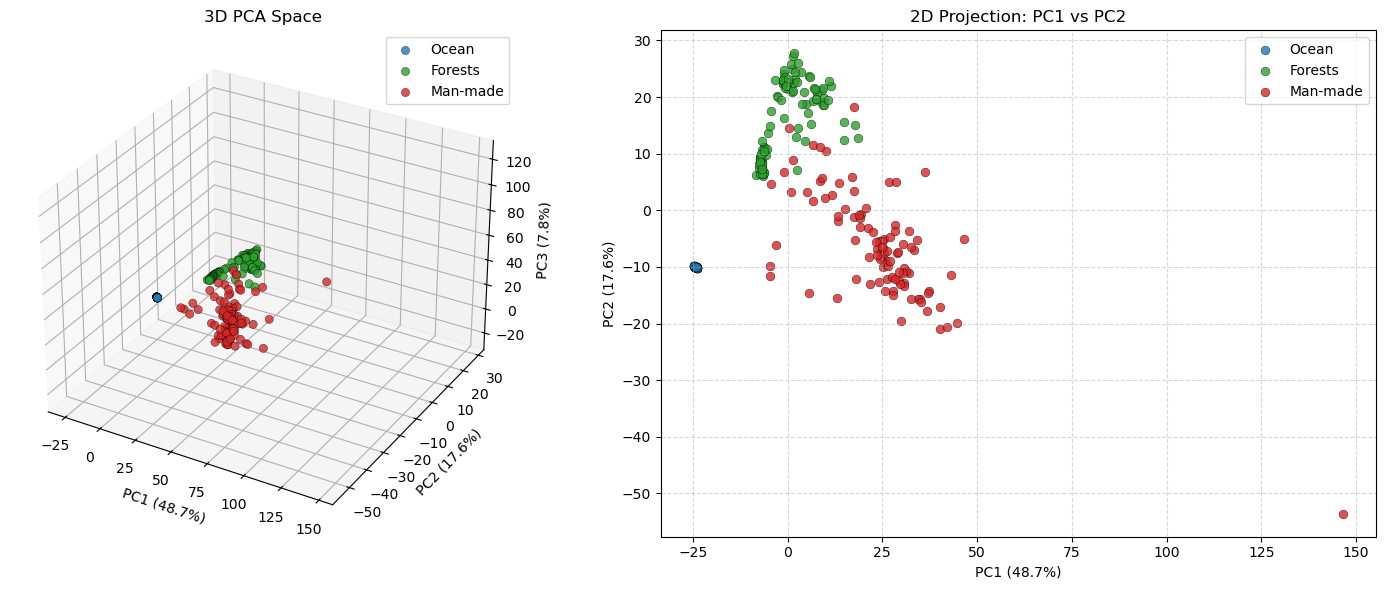

In [3]:
def extract_patches_from_scenes(scene_list, patch_size=16, n_patches_per_class=100):
    patches, labels = [], []
    for class_id, img in enumerate(scene_list):
        H, W, _ = img.shape
        for _ in range(n_patches_per_class):
            r = np.random.randint(0, H - patch_size)
            c = np.random.randint(0, W - patch_size)
            patches.append(img[r:r+patch_size, c:c+patch_size].flatten())
            labels.append(class_id)
    return np.array(patches), np.array(labels)

X_patches, y_labels = extract_patches_from_scenes(
    [ocean_img, forest_img, urban_img], patch_size=16, n_patches_per_class=100
)
print(f'Patches shape: {X_patches.shape}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_patches)

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_
print(f'Explained variance (PC1, PC2, PC3): {np.round(explained_var * 100, 2)}%')
print(f'Total explained variance: {np.sum(explained_var)*100:.2f}%')

class_names = {0: 'Ocean', 1: 'Forests', 2: 'Man-made'}
colors = {0: '#1f77b4', 1: '#2ca02c', 2: '#d62728'}

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(121, projection='3d')
for cid in [0, 1, 2]:
    idx = y_labels == cid
    ax1.scatter(X_pca[idx, 0], X_pca[idx, 1], X_pca[idx, 2],
                c=colors[cid], label=class_names[cid], alpha=0.8, s=35, edgecolors='k', linewidth=0.3)

ax1.set_xlabel(f'PC1 ({explained_var[0]*100:.1f}%)')
ax1.set_ylabel(f'PC2 ({explained_var[1]*100:.1f}%)')
ax1.set_zlabel(f'PC3 ({explained_var[2]*100:.1f}%)')
ax1.set_title('3D PCA Space')
ax1.legend()

ax2 = fig.add_subplot(122)
for cid in [0, 1, 2]:
    idx = y_labels == cid
    ax2.scatter(X_pca[idx, 0], X_pca[idx, 1],
                c=colors[cid], label=class_names[cid], alpha=0.8, s=40, edgecolors='k', linewidth=0.3)
ax2.set_xlabel(f'PC1 ({explained_var[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({explained_var[1]*100:.1f}%)')
ax2.set_title('2D Projection: PC1 vs PC2')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

### Observations for Task 1

The three land-cover classes clearly cluster in the PC space, with ocean, forests, and man-made forming separate groups.
- PC1 mostly captures overall brightness, separating the dark ocean from bright man-made areas.
- PC2 captures the contrast between NIR and visible bands, which separates forests from the other two classes.
- PC3 reflects local texture and variance inside the patches, such as the urban street grid.

## Task 2 Super-Resolution on Real Sentinel-2 Images with Autoencoders

Here we adapt the MNIST autoencoder (using MaxPooling2D, UpSampling2D, MSE loss, and 3 RGB channels) for Super-Resolution on real Sentinel-2 imagery.
- We fetch a real 10 m Sentinel-2 RGB image (bands B4, B3, B2) over Warsaw via Google Earth Engine and split it into 32x32x3 high-resolution patches.
- To create low-resolution inputs, we downsample each patch by 2x to 16x16x3 and upscale it back to 32x32x3 using bilinear interpolation.
- We compare the baseline autoencoder (3x MaxPooling2D bottleneck of size 4x4x8 and UpSampling2D decoder) against an improved Residual SR-CNN that removes MaxPooling2D, adds a residual skip connection, and uses MAE loss.

In [4]:
# Fetch real 10m Sentinel-2 RGB image over Warsaw
hr_aoi = ee.Geometry.Point([21.0122, 52.2297]).buffer(2500).bounds()
hr_full = download_ee_image_as_array(
    get_s2_composite(hr_aoi, ['B4', 'B3', 'B2']),
    hr_aoi, scale=10, norm_factor=3500.0
)
print('HR Sentinel-2 image shape:', hr_full.shape)

patch_size = 32
hr_patches = []
for i in range(0, hr_full.shape[0] - patch_size + 1, 16):
    for j in range(0, hr_full.shape[1] - patch_size + 1, 16):
        hr_patches.append(hr_full[i:i+patch_size, j:j+patch_size])

hr_patches = np.array(hr_patches)
indices = np.random.permutation(len(hr_patches))
hr_patches = hr_patches[indices]

split = int(0.8 * len(hr_patches))
y_train_hr, y_test_hr = hr_patches[:split], hr_patches[split:]

def degrade_images(images, scale=2):
    h, w = images.shape[1], images.shape[2]
    lr_small = np.zeros((len(images), h // scale, w // scale, images.shape[3]), dtype=np.float32)
    lr_up = np.zeros_like(images)
    for idx, img in enumerate(images):
        small = transform.resize(img, (h // scale, w // scale), anti_aliasing=True)
        lr_small[idx] = small
        lr_up[idx] = transform.resize(small, (h, w), order=1)
    return lr_small, lr_up

x_train_lr_small, x_train_lr = degrade_images(y_train_hr, scale=2)
x_test_lr_small, x_test_lr = degrade_images(y_test_hr, scale=2)

print(f'Train LR(small)->HR: {x_train_lr_small.shape} -> {y_train_hr.shape}')
print(f'Test  LR(small)->HR: {x_test_lr_small.shape} -> {y_test_hr.shape}')

HR Sentinel-2 image shape: (501, 813, 3)


Train LR(small)->HR: (1176, 16, 16, 3) -> (1176, 32, 32, 3)
Test  LR(small)->HR: (294, 16, 16, 3) -> (294, 32, 32, 3)


In [5]:
# 1. Baseline autoencoder (adapted from the MNIST lab code)
input_img = Input(shape=(32, 32, 3))

x = Conv2D(16, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x) # bottleneck: (4, 4, 8)

encoder_base = Model(input_img, encoded)

input_rep = Input(shape=(4, 4, 8))
x = Conv2D(8, (3, 3), activation='relu', padding='same')(input_rep)
x = UpSampling2D((2, 2))(x)
x = Conv2D(8, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

decoder_base = Model(input_rep, decoded)

autoencoder_base = Model(input_img, decoder_base(encoder_base(input_img)))
autoencoder_base.compile(optimizer='adam', loss='mse')

history_base = autoencoder_base.fit(
    x_train_lr, y_train_hr,
    epochs=40,
    batch_size=32,
    shuffle=True,
    validation_data=(x_test_lr, y_test_hr),
    verbose=0
)

preds_base = autoencoder_base.predict(x_test_lr, verbose=0)
print(f"Baseline autoencoder - final val_loss (MSE): {history_base.history['val_loss'][-1]:.5f}")

Baseline autoencoder - final val_loss (MSE): 0.00560


In [6]:
from tensorflow.keras.layers import Concatenate, Lambda

# 2. Improved SR-CNN (no MaxPooling + residual skip connection + MAE loss)
def build_improved_sr_model():
    inp = Input(shape=(32, 32, 3))
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(inp)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    residual = Conv2D(3, (3, 3), activation='linear', padding='same')(x)
    out = Add()([inp, residual])
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mae')
    return model

# 3. U-Net Autoencoder (keeps MaxPooling, adds skip connections + MAE loss)
def build_unet_sr_model():
    inp = Input(shape=(32, 32, 3))
    e1 = Conv2D(32, (3, 3), activation='relu', padding='same')(inp)
    p1 = MaxPooling2D((2, 2), padding='same')(e1)
    e2 = Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    p2 = MaxPooling2D((2, 2), padding='same')(e2)

    b = Conv2D(64, (3, 3), activation='relu', padding='same')(p2)

    u2 = UpSampling2D((2, 2))(b)
    d2 = Concatenate()([u2, e2])
    d2 = Conv2D(64, (3, 3), activation='relu', padding='same')(d2)

    u1 = UpSampling2D((2, 2))(d2)
    d1 = Concatenate()([u1, e1])
    d1 = Conv2D(32, (3, 3), activation='relu', padding='same')(d1)

    residual = Conv2D(3, (3, 3), activation='linear', padding='same')(d1)
    out = Add()([inp, residual])
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mae')
    return model

# 4. Sub-Pixel SR-ResNet (native 16x16 LR input + ResBlocks + PixelShuffle + MAE/SSIM loss)
def mae_ssim_loss(y_true, y_pred):
    mae = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim_val = tf.reduce_mean(tf.image.ssim(y_true, tf.clip_by_value(y_pred, 0.0, 1.0), max_val=1.0))
    return 0.8 * mae + 0.2 * (1.0 - ssim_val)

def build_pixelshuffle_resnet():
    inp = Input(shape=(16, 16, 3))
    x = Conv2D(48, (3, 3), activation='relu', padding='same')(inp)
    head = x

    # two residual blocks in LR space
    for _ in range(2):
        r = Conv2D(48, (3, 3), activation='relu', padding='same')(x)
        r = Conv2D(48, (3, 3), activation='linear', padding='same')(r)
        x = Add()([x, r])
    x = Add()([x, head])

    # sub-pixel convolution (PixelShuffle 2x: 16x16x12 -> 32x32x3)
    x = Conv2D(3 * 4, (3, 3), activation='linear', padding='same')(x)
    residual_hr = Lambda(lambda t: tf.nn.depth_to_space(t, 2), output_shape=(32, 32, 3))(x)
    base_up = Lambda(lambda t: tf.image.resize(t, (32, 32), method='bilinear'), output_shape=(32, 32, 3))(inp)
    out = Add()([base_up, residual_hr])

    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=mae_ssim_loss)
    return model

sr_improved = build_improved_sr_model()
sr_improved.fit(x_train_lr, y_train_hr, epochs=35, batch_size=32, shuffle=True, validation_data=(x_test_lr, y_test_hr), verbose=0)
preds_improved = np.clip(sr_improved.predict(x_test_lr, verbose=0), 0.0, 1.0)

sr_unet = build_unet_sr_model()
sr_unet.fit(x_train_lr, y_train_hr, epochs=35, batch_size=32, shuffle=True, validation_data=(x_test_lr, y_test_hr), verbose=0)
preds_unet = np.clip(sr_unet.predict(x_test_lr, verbose=0), 0.0, 1.0)

sr_ps = build_pixelshuffle_resnet()
sr_ps.fit(x_train_lr_small, y_train_hr, epochs=35, batch_size=32, shuffle=True, validation_data=(x_test_lr_small, y_test_hr), verbose=0)
preds_ps = np.clip(sr_ps.predict(x_test_lr_small, verbose=0), 0.0, 1.0)

def evaluate_sr(sr_imgs, hr_imgs, name=""):
    psnr_vals = [psnr(hr, sr, data_range=1.0) for hr, sr in zip(hr_imgs, sr_imgs)]
    ssim_vals = [ssim(hr, sr, data_range=1.0, channel_axis=-1) for hr, sr in zip(hr_imgs, sr_imgs)]
    print(f"{name:38s} | PSNR: {np.mean(psnr_vals):6.2f} dB | SSIM: {np.mean(ssim_vals):.4f}")

print("=== RECONSTRUCTION QUALITY (TEST SET) ===")
evaluate_sr(x_test_lr,      y_test_hr, "1. LR Input (Bilinear)")
evaluate_sr(preds_base,     y_test_hr, "2. Baseline Autoencoder (Pooling)")
evaluate_sr(preds_improved, y_test_hr, "3. Residual SR-CNN (No Pooling)")
evaluate_sr(preds_unet,     y_test_hr, "4. U-Net Autoencoder (Skip Conn)")
evaluate_sr(preds_ps,       y_test_hr, "5. PixelShuffle ResNet (MAE+SSIM)")

=== RECONSTRUCTION QUALITY (TEST SET) ===
1. LR Input (Bilinear)                 | PSNR:  27.79 dB | SSIM: 0.8120


2. Baseline Autoencoder (Pooling)      | PSNR:  23.17 dB | SSIM: 0.4519


3. Residual SR-CNN (No Pooling)        | PSNR:  30.95 dB | SSIM: 0.9175
4. U-Net Autoencoder (Skip Conn)       | PSNR:  31.19 dB | SSIM: 0.9222


5. PixelShuffle ResNet (MAE+SSIM)      | PSNR:  31.17 dB | SSIM: 0.9251


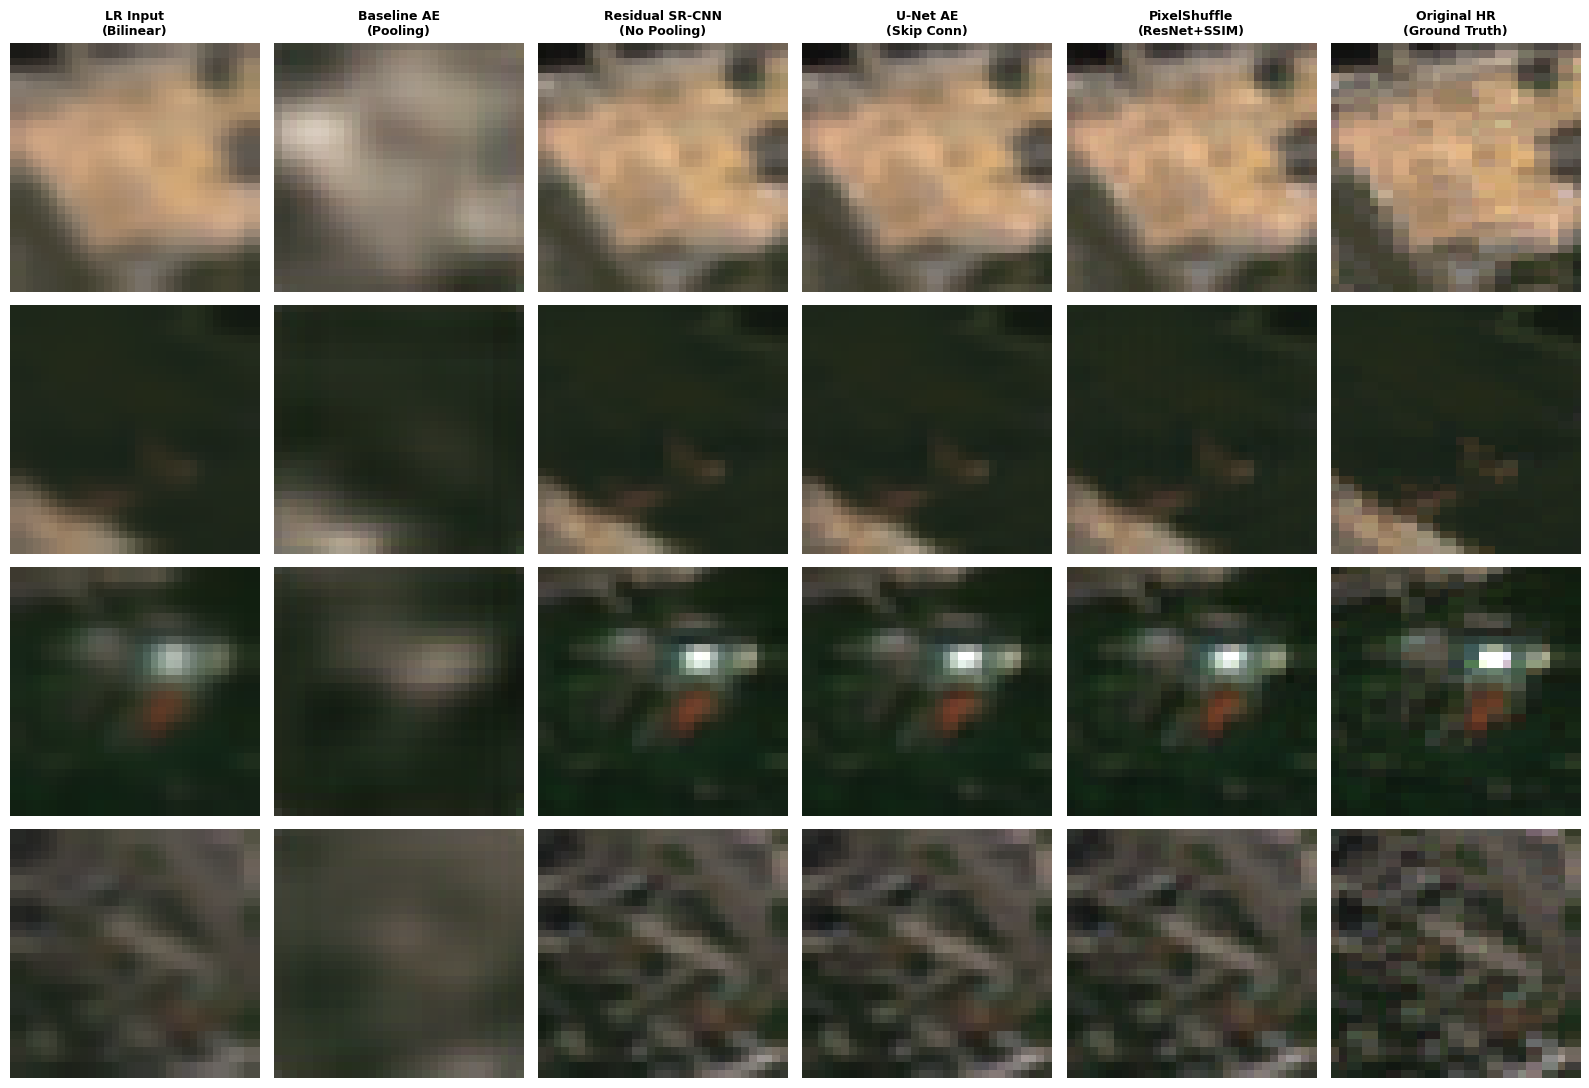

In [7]:
n_show = 4
fig, axes = plt.subplots(n_show, 6, figsize=(16, 11))
titles = [
    "LR Input\n(Bilinear)",
    "Baseline AE\n(Pooling)",
    "Residual SR-CNN\n(No Pooling)",
    "U-Net AE\n(Skip Conn)",
    "PixelShuffle\n(ResNet+SSIM)",
    "Original HR\n(Ground Truth)"
]

for i in range(n_show):
    imgs = [x_test_lr[i], preds_base[i], preds_improved[i], preds_unet[i], preds_ps[i], y_test_hr[i]]
    for j in range(6):
        axes[i, j].imshow(imgs[j])
        if i == 0:
            axes[i, j].set_title(titles[j], fontsize=9, fontweight='bold')
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

### Answers for Task 2

Does the provided autoencoder enhance the resolution?
No, it makes the image much blurrier instead of enhancing it. The three MaxPooling2D layers shrink the 32x32 input down to 4x4, which throws away most spatial details like edges, roads, and textures. Because of this bottleneck, the decoder only recovers blurry average colors, so both PSNR and SSIM drop below the low-resolution input.

How can we make it work better?
We tested several improvements directly above and they all clearly outperformed both the baseline autoencoder and the bilinear LR input
- Removing MaxPooling2D (Residual SR-CNN) keeps full spatial resolution so fine details are not lost.
- Adding U-Net skip connections allows an encoder-decoder with pooling to pass high-resolution features directly to the decoder.
- Using residual skip connections lets the network predict only the missing high-frequency details instead of rebuilding the whole image.
- Using MAE + SSIM loss instead of MSE avoids averaging out edges and gives sharper textures.
- Using sub-pixel convolution (PixelShuffle with ResBlocks) processes the native 16x16 LR image and upscales at the very end.